In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from data_preprocessing import load_data, clean_data, LABEL_COLS

In [2]:
df_raw = load_data('../data/train.csv')
print(df_raw.shape)
df_raw.head()

(159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [3]:
df_raw.info()
df_raw.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64
toxic            9.58
severe_toxic     1.00
obscene          5.29
threat           0.30
insult           4.94
identity_hate    0.88
dtype: float64


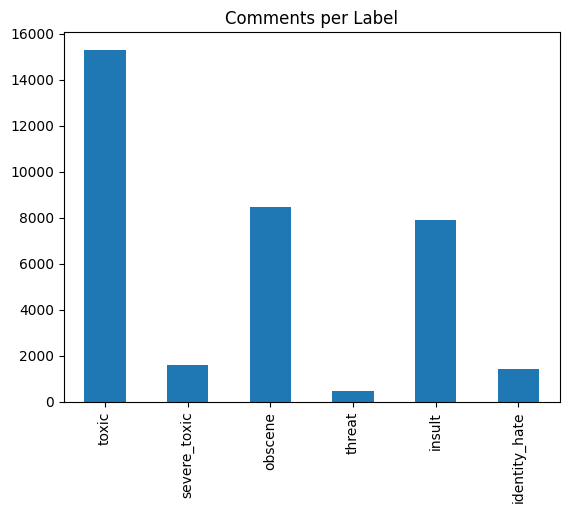

In [4]:
print(df_raw[LABEL_COLS].sum())
print((df_raw[LABEL_COLS].mean() * 100).round(2))

df_raw[LABEL_COLS].sum().plot(kind='bar')
plt.title('Comments per Label')
plt.show()

In [5]:
df_raw['label_count'] = df_raw[LABEL_COLS].sum(axis=1)
print(df_raw['label_count'].value_counts().sort_index())

label_count
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64


In [6]:
df_raw['length'] = df_raw['comment_text'].str.len()
print(df_raw.groupby('toxic')['length'].mean())

toxic
0    404.549339
1    295.246044
Name: length, dtype: float64


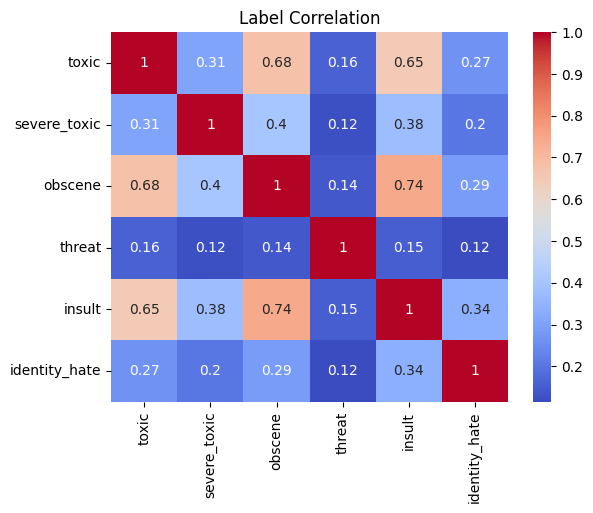

In [7]:
sns.heatmap(df_raw[LABEL_COLS].corr(), annot=True, cmap='coolwarm')
plt.title('Label Correlation')
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

df = clean_data(df_raw[['id', 'comment_text'] + LABEL_COLS])

X = df['comment_text']
y = df[LABEL_COLS]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df['toxic']
)

vectorizer = TfidfVectorizer(stop_words='english', max_features=30000, ngram_range=(1, 2), min_df=5)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape, X_test_tfidf.shape)

(127656, 30000) (31915, 30000)


In [9]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, roc_auc_score

lr_model = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, class_weight='balanced', solver='liblinear')
)
lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)
print(classification_report(y_test, lr_pred, target_names=LABEL_COLS, zero_division=0))
print('Macro F1:', f1_score(y_test, lr_pred, average='macro', zero_division=0))
print('Macro ROC-AUC:', roc_auc_score(y_test, lr_model.decision_function(X_test_tfidf), average='macro'))

               precision    recall  f1-score   support

        toxic       0.65      0.86      0.74      3059
 severe_toxic       0.26      0.85      0.40       311
      obscene       0.68      0.89      0.77      1710
       threat       0.21      0.61      0.31        97
       insult       0.56      0.86      0.68      1590
identity_hate       0.23      0.81      0.36       289

    micro avg       0.55      0.86      0.67      7056
    macro avg       0.43      0.81      0.54      7056
 weighted avg       0.60      0.86      0.70      7056
  samples avg       0.06      0.08      0.07      7056

Macro F1: 0.5431016133223626
Macro ROC-AUC: 0.9797711271184175


In [10]:
from sklearn.svm import LinearSVC

svm_model = OneVsRestClassifier(LinearSVC(class_weight='balanced'))
svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)
print(classification_report(y_test, svm_pred, target_names=LABEL_COLS, zero_division=0))
print('Macro F1:', f1_score(y_test, svm_pred, average='macro', zero_division=0))
print('Macro ROC-AUC:', roc_auc_score(y_test, svm_model.decision_function(X_test_tfidf), average='macro'))

               precision    recall  f1-score   support

        toxic       0.66      0.82      0.73      3059
 severe_toxic       0.29      0.68      0.40       311
      obscene       0.70      0.84      0.77      1710
       threat       0.30      0.36      0.33        97
       insult       0.56      0.78      0.66      1590
identity_hate       0.30      0.60      0.40       289

    micro avg       0.59      0.80      0.68      7056
    macro avg       0.47      0.68      0.55      7056
 weighted avg       0.61      0.80      0.69      7056
  samples avg       0.06      0.07      0.07      7056

Macro F1: 0.5480202922213654
Macro ROC-AUC: 0.966196862834232


               Logistic Regression  Linear SVM
toxic                        0.742       0.734
severe_toxic                 0.395       0.402
obscene                      0.774       0.766
threat                       0.309       0.330
insult                       0.675       0.656
identity_hate                0.363       0.400


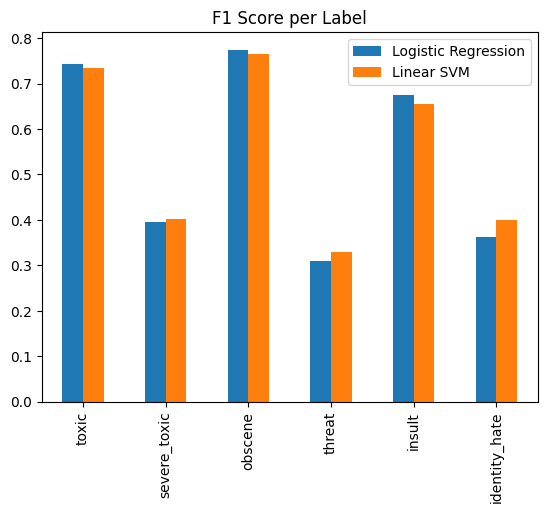

In [11]:
from sklearn.metrics import f1_score

lr_f1 = f1_score(y_test, lr_pred, average=None, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, average=None, zero_division=0)

compare = pd.DataFrame({'Logistic Regression': lr_f1, 'Linear SVM': svm_f1}, index=LABEL_COLS)
print(compare.round(3))
compare.plot(kind='bar')
plt.title('F1 Score per Label')
plt.show()

In [12]:
words = np.array(vectorizer.get_feature_names_out())
coef = lr_model.estimators_[0].coef_[0]
top_idx = np.argsort(coef)[-10:]
print(words[top_idx])

['asshole' 'suck' 'crap' 'bullshit' 'ass' 'idiot' 'stupid' 'shit'
 'fucking' 'fuck']


In [13]:
test_comments = [
    'Thank you for the helpful edit, great work.',
    'You are so stupid, just shut up.',
    'The article needs more references and sources.',
]

test_tfidf = vectorizer.transform([c.lower() for c in test_comments])
test_pred = lr_model.predict(test_tfidf)

for i in range(len(test_comments)):
    found = [LABEL_COLS[j] for j in range(len(LABEL_COLS)) if test_pred[i][j] == 1]
    print(test_comments[i], '->', found)

Thank you for the helpful edit, great work. -> []
You are so stupid, just shut up. -> ['toxic', 'severe_toxic', 'obscene', 'insult']
The article needs more references and sources. -> []
